## GPT2 Architecture Part 4: Shortcut Connection

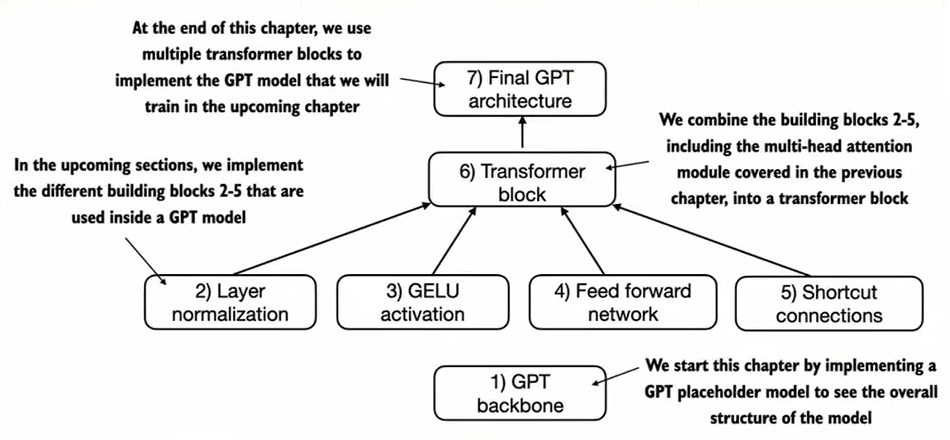

In [4]:
from IPython.display import Image
Image("images/stage_1_3_GELU/stages.png", width=800)

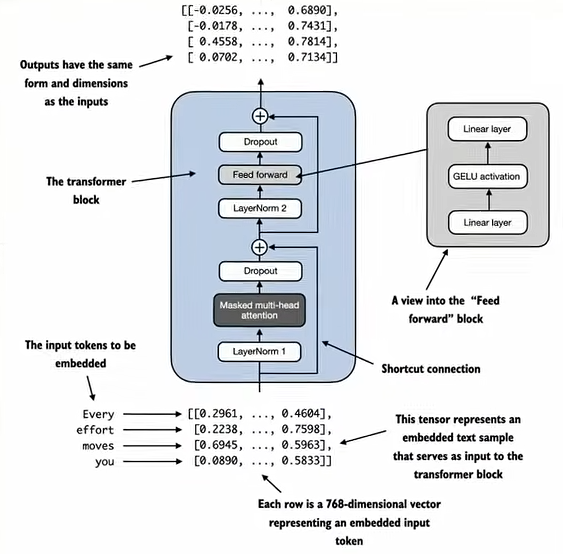

In [5]:
Image("images/stage_1_3_GELU/transformer_block.png", width=800)

In [6]:
import torch
import torch.nn as nn
torch.set_printoptions(sci_mode=False)



In [7]:
class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) * 
            (x + 0.044715 * torch.pow(x, 3))
            ))

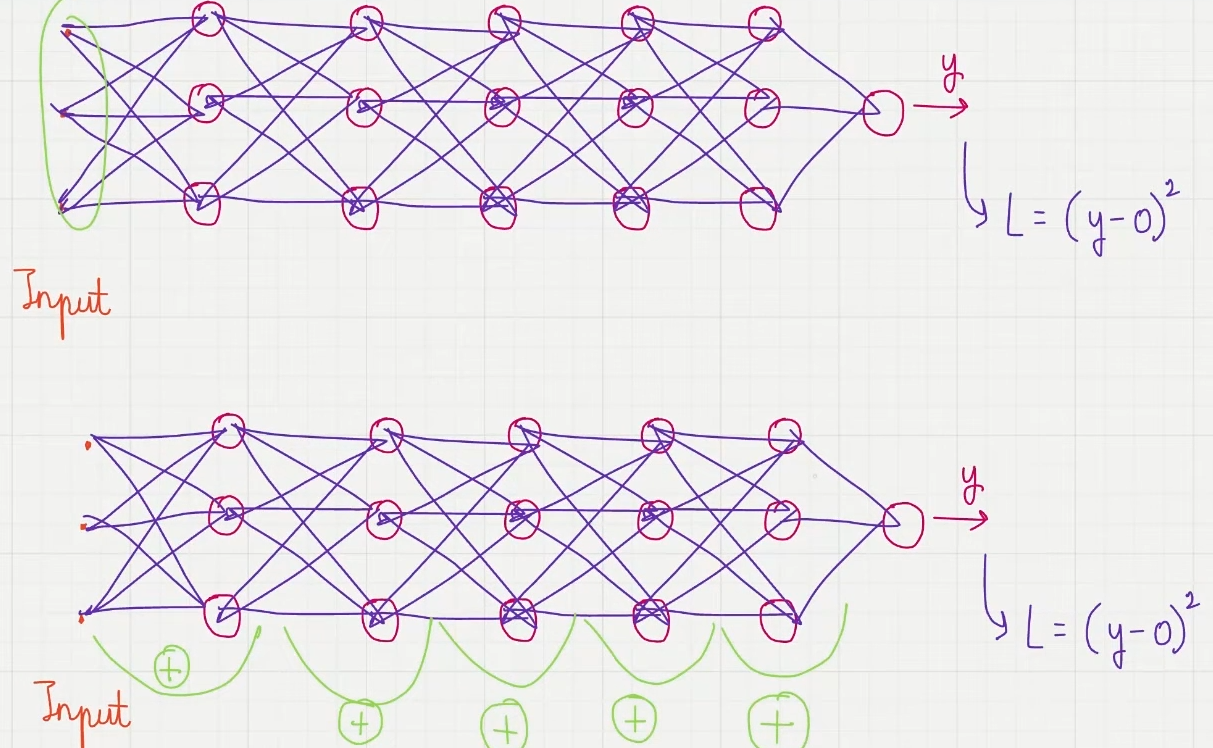

In [8]:
Image("images/stage_1_4_shortcut_conn/nn_layers.png", width=800)

In [11]:
class ExampleDeepNeuralNetwork(nn.Module):
    def __init__(self, layer_sizes, use_shortcut):
        super().__init__()
        self.use_shortcut = use_shortcut
        self.layers = nn.ModuleList([
            nn.Sequential(nn.Linear(layer_sizes[0], layer_sizes[1]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[1], layer_sizes[2]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[2], layer_sizes[3]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[3], layer_sizes[4]), GELU()),
            nn.Sequential(nn.Linear(layer_sizes[4], layer_sizes[5]), GELU()),
        ])

    def forward(self, x):
        for layer in self.layers:
            # compute output of the layer
            layer_output = layer(x)
            # check if shortcut connection is to be used
            if self.use_shortcut and x.shape == layer_output.shape:
                x = x + layer_output  # Add the input to the output of the layer
            else:
                x = layer_output  # Just pass through the layer
        return x

- This is an implementation of deep neural networks with 5 lyers, each consisting of a Linear Layer, and GELU activation function.

- In FORWARD pass, we iteratively pass the inputs through the layers and OPTIONALL add the shortcut connections if the self.use_shortcut= TRUE 

#### Let's use the Neural Network without Shortcut Connections 

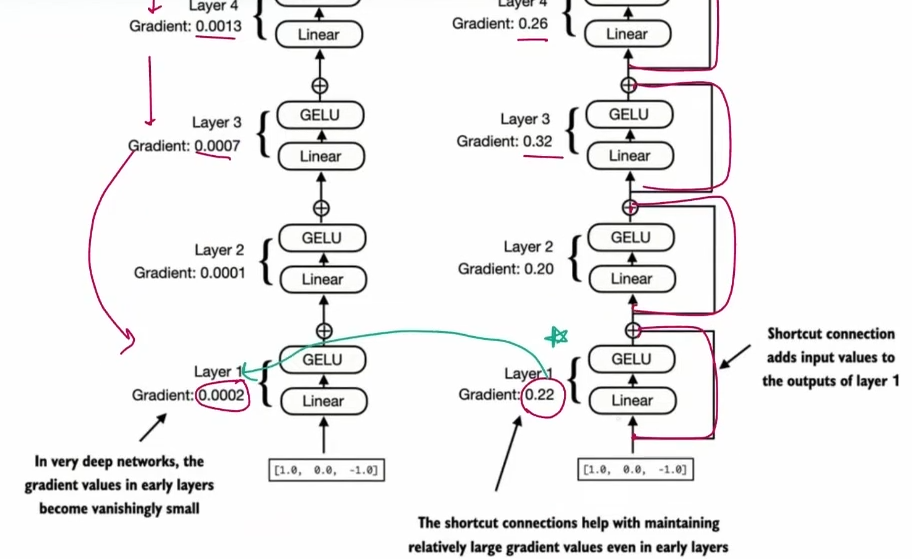

In [9]:
Image("images/stage_1_4_shortcut_conn/nn_with_without_shortcut_conn.png", width=700)

In [12]:
layer_sizes = [3,3,3,3,3,1] 
sample_input = torch.tensor([[1.0, 0.0, -1.0 ]])
torch.manual_seed(123)  # For reproducibility
model_without_shortcut = ExampleDeepNeuralNetwork(layer_sizes, use_shortcut=False)


In [13]:
def print_gradients(model, x):
    # forward pass
    output = model(x)
    target = torch.tensor([[0.0]])  # Example target for loss computation

    # calculate loss
    loss_fn = nn.MSELoss()
    loss = loss_fn(output, target)

    # backward pass
    loss.backward()

    for name, param in model.named_parameters():
        if "weight" in name:
            # print mean absolute gradient for weights
            print(f"{name} has gradient mean of {param.grad.abs().mean().item()}")


- In this function we specify a loss function that computes how close the model output and a user-specified target is.

- Then, when calling loss.backward() , Pytorch computes the loss gradient for each layer of the model.

- We can iterate through the weight parameters via model.named_parameters().

- Suppose we have 3x3 weight parameter matrix for a given layer.

- In that case, this layer will have 3x3 gradient values, and we print the mean absolute gradient of these 3x3 gradient values to obtain a single gradient value per layer to compute the gradients between layers more easily.

- In short, the .backward() method is a convenient method in Pytorch that computes loss gradients, which are required during model training 

In [14]:
print("Gradients without shortcut connections:")
print_gradients(model_without_shortcut, sample_input)

Gradients without shortcut connections:
layers.0.0.weight has gradient mean of 0.00020173587836325169
layers.1.0.weight has gradient mean of 0.0001201116101583466
layers.2.0.weight has gradient mean of 0.0007152041653171182
layers.3.0.weight has gradient mean of 0.001398873864673078
layers.4.0.weight has gradient mean of 0.005049646366387606


- As we can see here, gradients become smaller as we progress from layer to layer 0. This phenomenon is called VANISHING GRADIENT PROBLEM

#### Model with SKIP connections

In [15]:
torch.manual_seed(123)  # For reproducibility
model_with_shortcut = ExampleDeepNeuralNetwork(layer_sizes, use_shortcut=True)

print("\nGradients with shortcut connections:")
print_gradients(model_with_shortcut, sample_input)


Gradients with shortcut connections:
layers.0.0.weight has gradient mean of 0.22169792652130127
layers.1.0.weight has gradient mean of 0.20694106817245483
layers.2.0.weight has gradient mean of 0.32896995544433594
layers.3.0.weight has gradient mean of 0.2665732502937317
layers.4.0.weight has gradient mean of 1.3258541822433472


- We can see here the values of GRADIENT stabilizes as we progress towards first layer (layer 0) and doesn't shrink to vanishingly small values.

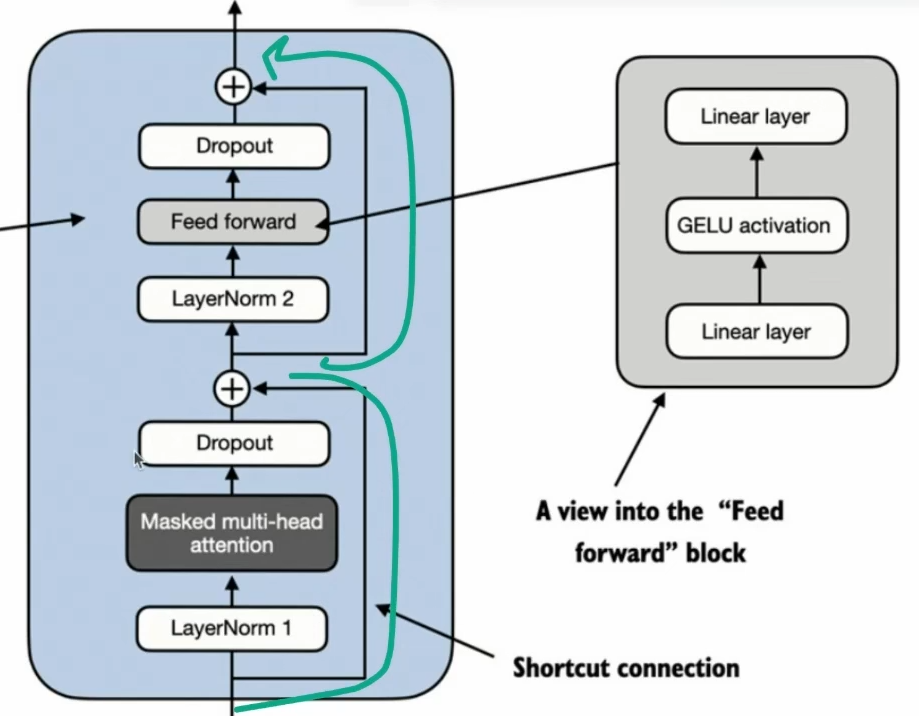

In [16]:
Image("images/stage_1_4_shortcut_conn/shorcut_in_transformer.png", width=700)